# 08 - Optimal policy vs real European storage behaviour (GIE AGSI+)

Does the optimal merchant policy look like what European storage actually does? The LSMC inventory paths of the
valuation (in % of working volume) are compared with the aggregated fill level of the NL + DE + FR storage fleet from
GIE AGSI+ (weighted by working gas volume), by day of the storage year (1 April = day 0).

* AGSI+ history: storage years 2017/18 to 2025/26 (complete years), plus the current year 2026/27 to date.
* Model: market case (EEX curve of 2026-11-17, backwardated) and contango case (synthetic seasonal curve), weekly
  LSMC policy on 10,000 out-of-sample paths, reference one-factor parameters.

Source: GIE AGSI+ (https://agsi.gie.eu).

In [1]:
import datetime as dt
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")

from gasstorage import plotting
from gasstorage.config import load_config
from gasstorage.data import agsi
from gasstorage.models.one_factor import OneFactorModel
from gasstorage.storage.contract import build_inputs
from gasstorage.storage.lsmc import lsmc_value

plotting.apply_style()
levels = agsi.load_storage_levels(["NL", "DE", "FR"], dt.date(2017, 4, 1), dt.date.today())
fleet = agsi.add_storage_year(agsi.aggregate_fill(levels, ["NL", "DE", "FR"], "NL+DE+FR"))
complete = [y for y in range(2017, 2026)]
hist = agsi.fill_profile(fleet, "NL+DE+FR", years=complete, quantiles=(0.1, 0.5, 0.9), min_years=5)
current = fleet[fleet["storage_year"] == 2026].set_index("day_of_storage_year")["full_pct"]
peaks = (
    fleet[fleet["storage_year"].isin([*complete, 2026])]
    .groupby("storage_year")["full_pct"]
    .agg(["min", "max"])
)
peaks.round(1).T

storage_year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
min,9.2,9.2,47.8,22.9,21.6,24.0,53.3,24.9,17.2,17.1
max,89.7,91.4,98.8,95.1,75.1,97.7,100.0,95.2,79.1,69.0


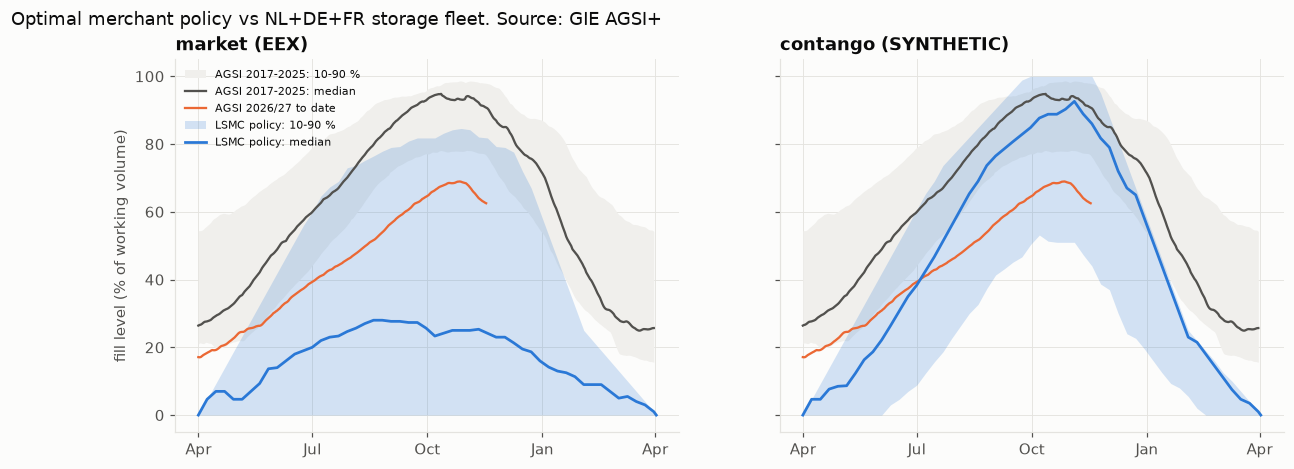

In [2]:
policies = {}
for case, path in {
    "market (EEX)": "configs/storage_default.yaml",
    "contango (SYNTHETIC)": "configs/storage_synthetic.yaml",
}.items():
    cfg = load_config(path)
    inp = build_inputs(cfg, "weekly")
    res = lsmc_value(
        inp,
        OneFactorModel.from_config(cfg.model),
        10_000,
        10_000,
        np.random.default_rng(12345),
        np.random.default_rng(67890),
        n_levels=101,
    )
    dates = inp.dates.append(
        pd.DatetimeIndex([inp.dates[-1] + pd.Timedelta(days=int(inp.days[-1]))])
    )
    day = (dates - pd.Timestamp(inp.dates[0])).days.to_numpy()
    q = np.percentile(100 * res.inventory / inp.contract.working_volume, [10, 50, 90], axis=1)
    policies[case] = pd.DataFrame({0.1: q[0], 0.5: q[1], 0.9: q[2]}, index=day)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
ticks = [0, 91, 183, 275, 365]
for ax, (case, prof) in zip(axes, policies.items(), strict=True):
    ax.fill_between(
        hist.index,
        hist[0.1],
        hist[0.9],
        color=plotting.NEUTRAL_FILL,
        lw=0,
        label="AGSI 2017-2025: 10-90 %",
    )
    ax.plot(
        hist.index, hist[0.5], color=plotting.TEXT_SECONDARY, lw=1.5, label="AGSI 2017-2025: median"
    )
    ax.plot(
        current.index,
        current.values,
        color=plotting.SERIES[1],
        lw=1.5,
        label="AGSI 2026/27 to date",
    )
    ax.fill_between(
        prof.index,
        prof[0.1],
        prof[0.9],
        color=plotting.SERIES[0],
        alpha=0.2,
        lw=0,
        label="LSMC policy: 10-90 %",
    )
    ax.plot(prof.index, prof[0.5], color=plotting.SERIES[0], lw=1.8, label="LSMC policy: median")
    ax.set_xticks(ticks, ["Apr", "Jul", "Oct", "Jan", "Apr"])
    ax.set_title(case)
axes[0].set_ylabel("fill level (% of working volume)")
axes[0].legend(loc="upper left", fontsize=7)
fig.suptitle(
    "Optimal merchant policy vs NL+DE+FR storage fleet. Source: GIE AGSI+", x=0.01, ha="left"
)
plotting.save_figure(fig, "08_policy_vs_agsi")
fig

In [3]:
def summary(prof):
    med = prof[0.5]
    return pd.Series(
        {
            "peak fill (%)": med.max(),
            "day of peak": int(med.idxmax()),
            "fill on 1 Nov (%)": float(np.interp(214, med.index, med.values)),
        }
    )


table = pd.DataFrame(
    {
        "AGSI median 2017-2025": summary(hist),
        "AGSI 2026/27 to date": summary(pd.DataFrame({0.5: current})),
        **{f"LSMC median, {c}": summary(p) for c, p in policies.items()},
    }
)
table.round(1)

,AGSI median 2017-2025,AGSI 2026/27 to date,"LSMC median, market (EEX)","LSMC median, contango (SYNTHETIC)"
peak fill (%),94.8,69.0,28.0,92.6
day of peak,194.0,209.0,140.0,217.0
fill on 1 Nov (%),94.0,68.4,25.0,91.6


## Findings

* **On a contango curve the optimal merchant policy looks like European storage history.** The median LSMC inventory
  on the synthetic seasonal curve peaks at about 93 % in early November and empties through the winter, close to the
  NL+DE+FR fleet median of 2017-2025 (peak about 95 % in mid-October). The real fleet ends winters with a larger
  cushion (about 25 % in March versus 0 % for a contract that must end empty) and starts refilling earlier.
* **On the backwardated 2027/28 curve the optimal policy barely fills.** Its median inventory peaks around 28 %:
  with summer gas priced above winter gas, filling only pays when the spot dips below the curve.
* **2026/27 is already unusual.** The fleet peaked at about 69 % this year, the lowest peak of the sample, in a market
  where summer 2027 trades above winter 2027/28. Part of the gap between the merchant optimum and actual behaviour
  comes from obligations that a merchant valuation ignores: security-of-supply rules, EU filling targets introduced
  in 2022, long-term contracts and the residual value of a cushion. Conversely, low fill levels are one reason the
  summer is bid up, which makes storage unattractive to fill: a loop that a single-asset valuation cannot capture.

Caveat: the model storage is a 1 TWh asset with illustrative rates that must start and end empty, the fleet is
about 500 TWh with heterogeneous sites and carries gas across years, so only shapes are comparable.